# Continuous Beam Analysis by the Direct Stiffness Method — consolidated programme

Companion notebook to *Python for Structural Analysis: Continuous Beam Analysis Using the Direct
Stiffness Method — A Step-by-Step Practical Guide for Civil Engineering Students*. It runs top to bottom in a fresh kernel and calls the functions in `beam_dsm.py`,
which holds the book's validated functions and the notebook's solver functions in one place.

**Scope.** Linear-elastic Euler–Bernoulli beam, constant EI, vertical-only supports (rotation free),
element UDLs, nodal vertical forces and internal downward point loads. This is an educational
engine, not a commercial structural-analysis package.

**Normalised stiffness.** The worked example uses `EI = 1`. For a beam of uniform EI, reactions,
shear forces and bending moments do **not** depend on EI. Displacements scale as 1/EI, so the
displacements printed here are normalised and must not be reported as physical deflections.

**Status of each capability.**

| Category | Content |
|---|---|
| Implemented and tested | Everything executed below; 99 automated tests and 115 benchmark checks (see README for what each means) |
| Not implemented (future work) | Rotational restraints, nodal moments, partial or triangular loads, hinges, springs, variable EI, support settlement, Timoshenko beams, plane frames |

In [1]:
import numpy as np
import matplotlib.pyplot as plt
import beam_dsm as dsm

np.set_printoptions(precision=4, suppress=True, linewidth=120)

## 1. The worked example (Chapter 2)

In [2]:
beam = dsm.define_beam()
for key, value in beam.items():
    print(f"{key:13s}", value)
print("\nTotal applied vertical load:",
      float(np.sum(beam['element_udl'] * np.diff(beam['nodes'])) + sum(beam['point_loads'].values())), "kN")

nodes         [ 0.   6.   8.  10.  12.5 14.1 17.  22. ]
element_udl   [60.  0.  0.  0. 20. 20. 80.]
point_loads   {2: 40.0, 3: 60.0, 5: 100.0}
support_nodes [0, 1, 4, 6, 7]
EI            1.0

Total applied vertical load: 1050.0 kN


## 2. Elements and degrees of freedom (Chapter 4)

In [3]:
elements = dsm.generate_elements(beam)
dof_numbers = dsm.generate_dofs(beam)
element_dofs = dsm.generate_element_dofs(elements, dof_numbers)
print("elements    :", elements)
print("element 0 DOFs:", element_dofs[0])

elements    : [[0 1]
 [1 2]
 [2 3]
 [3 4]
 [4 5]
 [5 6]
 [6 7]]
element 0 DOFs: [0 1 2 3]


## 3. Element stiffness and loads (Chapters 5 and 7)

In [4]:
k6 = dsm.beam_element_stiffness(beam["EI"], 6.0)
print("Stiffness matrix of a 6 m element (EI = 1):\n", k6)
print("\nEquivalent nodal loads, 60 kN/m over 6 m:", dsm.beam_element_load(60.0, 6.0))

Stiffness matrix of a 6 m element (EI = 1):
 [[ 0.0556  0.1667 -0.0556  0.1667]
 [ 0.1667  0.6667 -0.1667  0.3333]
 [-0.0556 -0.1667  0.0556 -0.1667]
 [ 0.1667  0.3333 -0.1667  0.6667]]

Equivalent nodal loads, 60 kN/m over 6 m: [-180. -180. -180.  180.]


## 4. Global assembly (Chapters 6 and 7)

In [5]:
K_global = dsm.assemble_global_stiffness(beam, elements, element_dofs)
F_global = dsm.assemble_global_load(beam, elements, element_dofs)
print("K shape:", K_global.shape, "| symmetric:", bool(np.allclose(K_global, K_global.T)))
print("Vertical entries of F:", F_global[0::2])

K shape: (16, 16) | symmetric: True
Vertical entries of F: [-180. -180.  -40.  -60.  -16. -145. -229. -200.]


## 5. Boundary conditions and solution (Chapter 8)

Only the **vertical** DOF is restrained at each support; rotations stay free. Restraining a
rotation would change the structural model.

In [6]:
restrained_dofs, free_dofs = dsm.generate_boundary_conditions(beam, dof_numbers)
K_reduced, F_reduced = dsm.reduce_system(K_global, F_global, free_dofs)
condition_number = dsm.validate_model_stability(K_reduced, beam["support_nodes"])
displacements = dsm.solve_beam_displacements(K_reduced, F_reduced, K_global.shape[0], free_dofs)
print("restrained DOFs:", list(restrained_dofs))
print("condition number of the reduced matrix: %.1f" % condition_number)
print("vertical displacements (normalised):", displacements[0::2])

restrained DOFs: [np.int64(0), np.int64(2), np.int64(8), np.int64(12), np.int64(14)]
condition number of the reduced matrix: 41.8
vertical displacements (normalised): [  0.       0.     102.9892  24.6635   0.     -26.4159   0.       0.    ]


## 6. Support reactions (Chapter 9)

In [7]:
reaction_vector, support_reactions = dsm.calculate_support_reactions(
    K_global, displacements, F_global, restrained_dofs
)
for name, r in zip("ABCDE", support_reactions):
    print(f"R_{name} = {r:10.6f} kN")
x = beam["nodes"]
print("\nSum of reactions      :", support_reactions.sum(), "kN")
print("Applied moment about A:", np.sum(x * F_global[0::2] + F_global[1::2]), "kN.m")
print("Reaction moment about A:", float(np.sum(support_reactions * x[beam['support_nodes']])), "kN.m")

R_A = 150.134983 kN
R_B = 283.462369 kN
R_C = 102.389420 kN
R_D = 350.286595 kN
R_E = 163.726633 kN

Sum of reactions      : 1050.0 kN
Applied moment about A: -12537.5 kN.m
Reaction moment about A: 12537.5 kN.m


## 7. Element end forces (Chapter 10)

In [8]:
element_end_forces = dsm.recover_all_element_end_forces(
    beam, elements, element_dofs, displacements,
    beam["element_udl"], beam.get("element_point_loads", [])
)
print("columns: V_left, M_left, V_right, M_right (element actions)\n")
print(element_end_forces)

columns: V_left, M_left, V_right, M_right (element actions)

[[ 150.135     0.      209.865  -179.1901]
 [  73.5974  179.1901  -73.5974  -31.9954]
 [  33.5974   31.9954  -33.5974   35.1993]
 [ -26.4026  -35.1993   26.4026  -30.8073]
 [  75.9868   30.8073  -43.9868   65.1715]
 [ -56.0132  -65.1715  114.0132 -181.3668]
 [ 236.2734  181.3668  163.7266    0.    ]]


## 8. Diagrams and moment extrema (Chapter 11)

In [9]:
element_diagrams = dsm.calculate_element_diagrams(beam, elements, element_end_forces)
sag, hog, _ = dsm.find_beam_moment_extrema(
    beam, elements, element_end_forces, beam["element_udl"], []
)
print("Maximum sagging moment: %+.6f kN.m at x = %.5f m" % (sag["moment"], sag["position"]))
print("Maximum hogging moment: %+.6f kN.m at x = %.5f m" % (hog["moment"], hog["position"]))

Maximum sagging moment: +187.837610 kN.m at x = 2.50225 m
Maximum hogging moment: -181.366836 kN.m at x = 17.00000 m


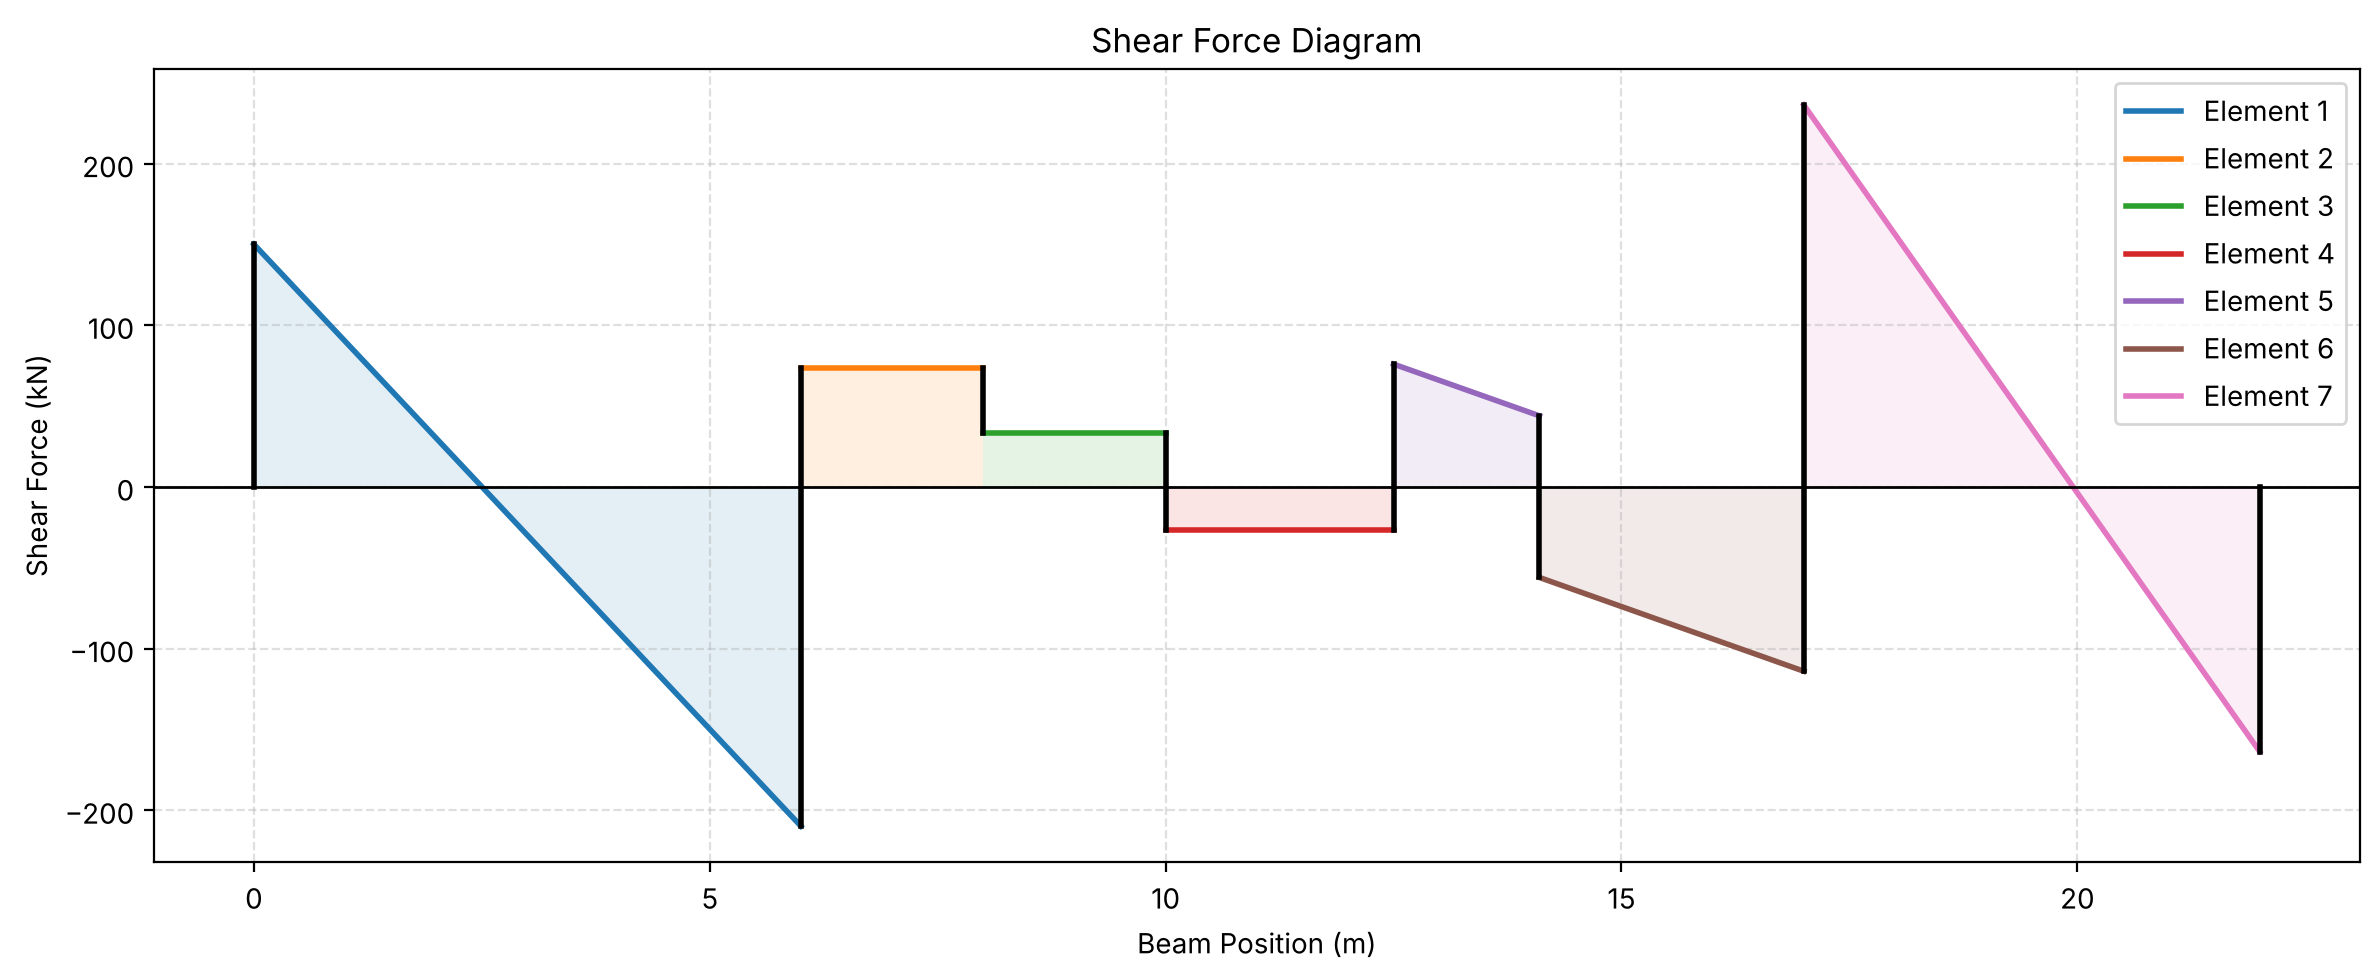

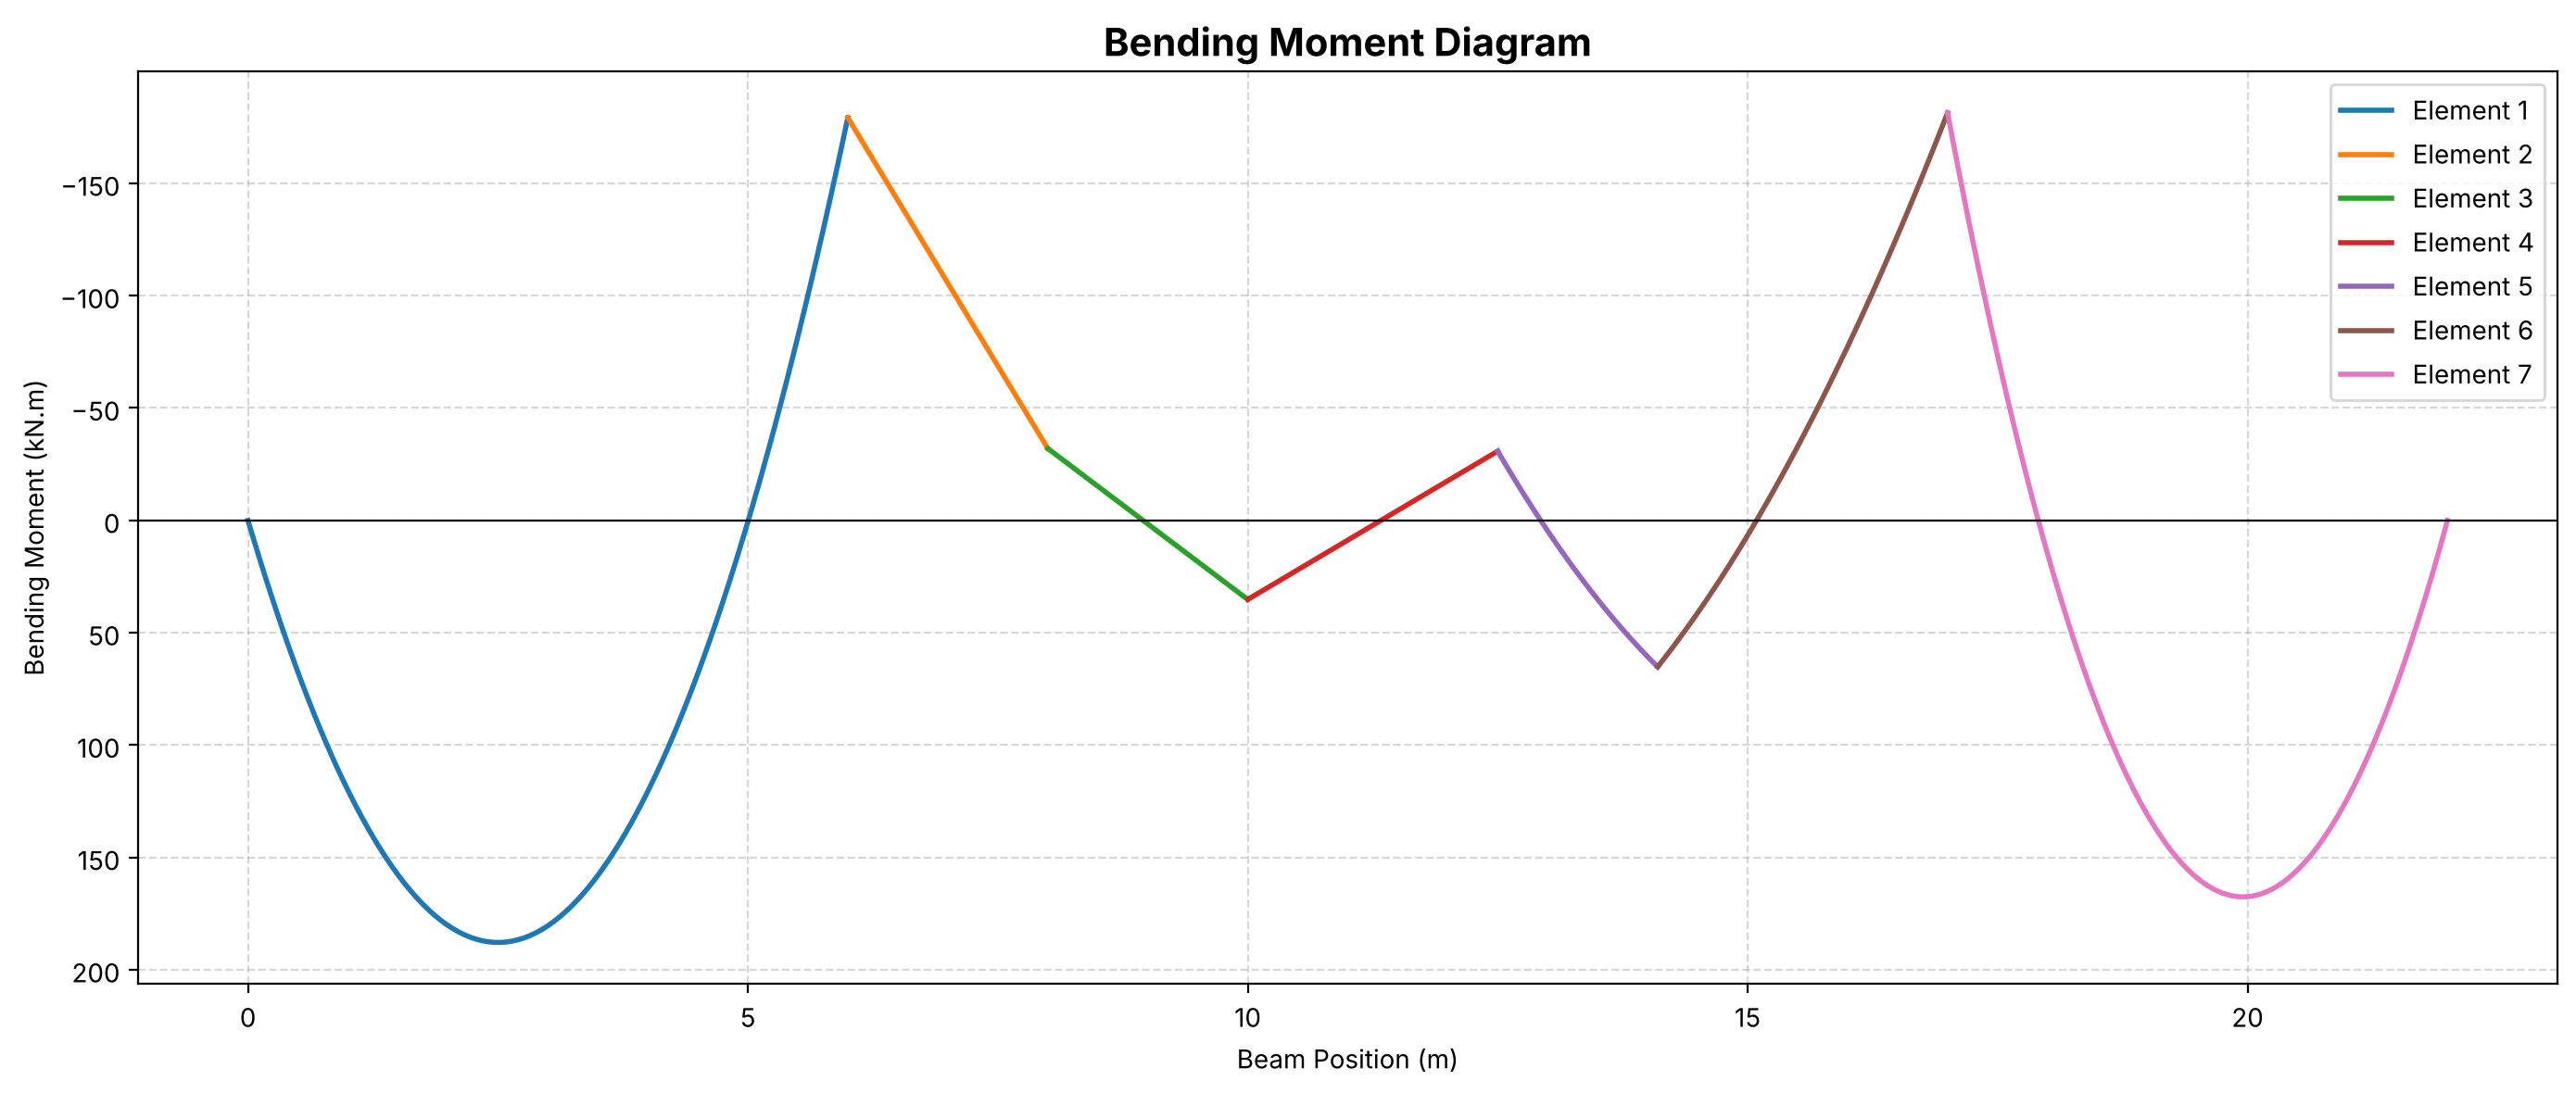

In [10]:
dsm.plot_shear_force_diagram(beam, element_diagrams)
plt.show()
dsm.plot_bending_moment_diagram(beam, element_diagrams)
plt.show()

## 9. Automated verification (Chapter 12)

The checks work as a **set**. Global equilibrium reads the applied load from the assembled load
vector, so on its own it cannot detect a wrong load vector; the independent load check recomputes
the loads from the inputs.

In [11]:
results = dsm.run_beam_analysis(beam)
checks = dsm.verify_engineering_results(results)


AUTOMATED ENGINEERING VERIFICATION
Input validation: PASS
  All input validation checks passed.
Global equilibrium: PASS
  Force error = 0.000e+00 kN; Moment error = 0.000e+00 kN.m
Stiffness matrix symmetry: PASS
  Maximum asymmetry = 0.000e+00
Support displacement: PASS
  Maximum restrained displacement = 0.000e+00
Element equilibrium: PASS
  Maximum element equilibrium error = 5.684e-14
Bending moment continuity: PASS
  Maximum moment discontinuity = 5.684e-14 kN.m
Independent load check: PASS
  Reactions minus loads from inputs: force 0.000e+00 kN; moment 0.000e+00 kN.m
Numerical finiteness: PASS
  All numerical results are finite.
------------------------------------------------
OVERALL ENGINEERING VERIFICATION: PASS


## 10. Independent confirmation by the Three-Moment equations (Chapter 12)

In [12]:
import sys
sys.path.insert(0, "tests")
from reference_three_moment import three_moment_reference

M_ref, R_ref = three_moment_reference()
ef = results["element_end_forces"]
M_dsm = np.array([ef[0, 3], ef[3, 3], ef[5, 3]])
print("Support   Three-Moment      Direct Stiffness   difference")
for name, a, b in zip("BCD", M_ref, M_dsm):
    print(f"   {name}    {a:12.6f}     {b:12.6f}     {abs(a - b):.1e}")
print("\nLargest reaction difference: %.1e kN" % np.max(np.abs(R_ref - results["support_reactions"])))

Support   Three-Moment      Direct Stiffness   difference
   B     -179.190099      -179.190099     4.4e-09
   C      -30.807310       -30.807310     4.0e-10
   D     -181.366836      -181.366836     4.3e-09

Largest reaction difference: 1.9e-09 kN


## 11. The whole programme in one call (Chapter 13)

`run_beam_analysis` performs steps 2 to 8 above, adding the stability check.

In [13]:
print("Identical to the step-by-step results:",
      bool(np.array_equal(results["displacements"], displacements)),
      bool(np.array_equal(results["element_end_forces"], element_end_forces)))

Identical to the step-by-step results: True True


## 12. Deflected shape and the mesh-refinement caveat (Chapter 18)

Nodal displacements are exact, but inside a loaded element the cubic Hermite shape is only an
approximation (a UDL deflection is quartic). The value from the original mesh can be tens of per
cent too small, so a maximum deflection is only quoted after refinement. Values are normalised
(EI = 1).

In [14]:
study = dsm.find_converged_maximum_deflection(beam, refinements=(1, 2, 4, 8, 16, 32))
print("refinement   max downward deflection   position")
for h in study["history"]:
    print(f"{h['refinement']:>6d}      {h['deflection']:>16.5f}        {h['position']:.3f} m")
print("\nconverged:", study["converged"], "| original mesh reaches only "
      f"{100 * study['original_mesh_deflection'] / study['deflection']:.0f}% of the converged value")

refinement   max downward deflection   position
     1            -417.37982        2.540 m
     2            -613.85584        2.796 m
     4            -614.59044        2.764 m
     8            -614.78107        2.757 m
    16            -614.81659        2.756 m
    32            -614.81900        2.756 m

converged: True | original mesh reaches only 68% of the converged value


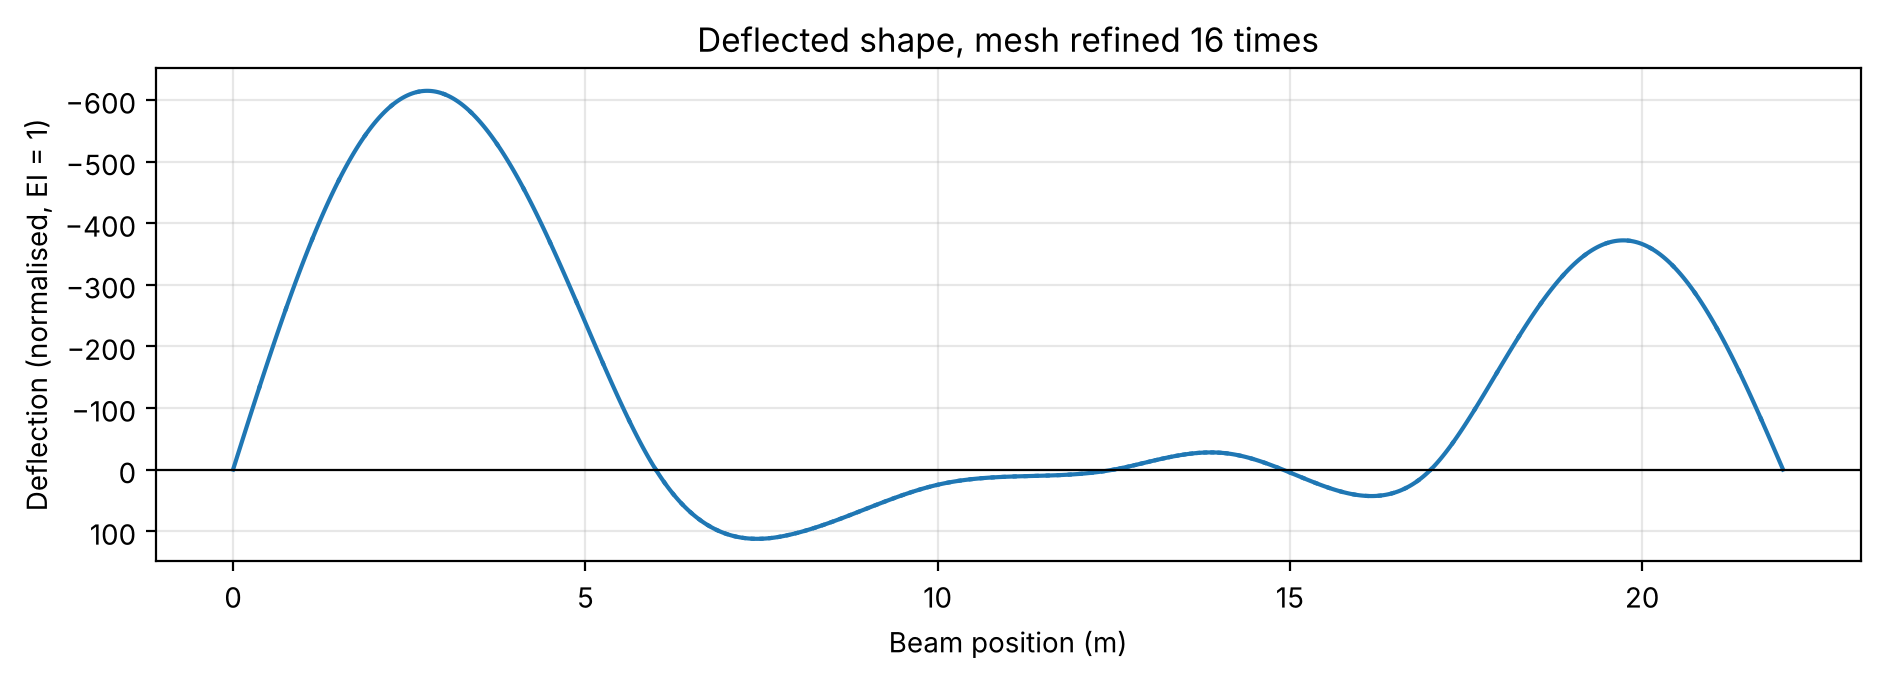

In [15]:
fine = dsm.run_beam_analysis(dsm.refine_beam(beam, 16))
shape = dsm.calculate_deflected_shape(fine["beam"], fine["elements"], fine["element_dofs"], fine["displacements"])
plt.figure(figsize=(11, 3.2))
for piece in shape:
    plt.plot(piece["x"], piece["deflection"], color="tab:blue")
plt.axhline(0, color="k", lw=0.8)
plt.gca().invert_yaxis()
plt.xlabel("Beam position (m)"); plt.ylabel("Deflection (normalised, EI = 1)")
plt.title("Deflected shape, mesh refined 16 times"); plt.grid(alpha=0.3)
plt.show()

## 13. Benchmark register (Chapter 19)

In [16]:
from benchmarks import register, summarise

records = register(dsm)
print(f"{'Test':4s} {'Case':46s} {'Models run':28s} {'Result':6s} {'Checks':6s} Max abs error")
for test, case, rep, ok, n, worst in summarise(records):
    print(f"{test:<4d} {case[:46]:46s} {rep[:28]:28s} {'PASS' if ok else 'FAIL':6s} {n:<6d} {worst:.1e}")
print(f"\n{len(records)} checks, {sum(not r['passed'] for r in records)} failed")

Test Case                                           Models run                   Result Checks Max abs error
1    Central point load, L = 10 m, P = 100 kN       1 element, internal load     PASS   5      0.0e+00
1    Central point load, L = 10 m, P = 100 kN       2 elements, nodal load       PASS   5      5.7e-14
2    Full-span UDL 20 kN/m                          1 element                    PASS   5      0.0e+00
2    Full-span UDL 20 kN/m                          4 elements                   PASS   5      2.3e-13
3    Eccentric point load, P = 100 kN at 4 m        1 element, internal load     PASS   5      0.0e+00
3    Eccentric point load, P = 100 kN at 4 m        2 elements, nodal load       PASS   5      0.0e+00
4    Two point loads, 40 kN at 3 m and 50 kN at 7 m 1 element, internal loads    PASS   9      5.7e-14
4    Two point loads, 40 kN at 3 m and 50 kN at 7 m 3 elements, nodal loads      PASS   5      1.1e-13
5    UDL 10 kN/m with 40 kN at midspan              1 element, inte

## 14. Second worked example: three spans with an overhang (Chapter 15)

Supports A, B, C, D at 0, 6, 14 and 20 m; free end at 23 m. Loads: 25 kN/m on AB, a 150 kN point load
3 m from B inside BC, 30 kN/m on the right-hand 3 m of CD, 20 kN/m on the overhang and 40 kN at the free end.
It is checked against an exact force-method reference that shares no code or method with the package.

In [17]:
from reference_force_method import solve_reference
beam2 = dsm.define_second_example_beam()
res2 = dsm.run_beam_analysis(beam2)
ref2 = solve_reference(**__import__("benchmarks").EXAMPLE2)
print("Support   Stiffness method (kN)   Force method, exact (kN)   Difference")
for name, calc, exact in zip("ABCD", res2["support_reactions"], ref2["reactions"]):
    print(f"   {name}      {calc:16.6f}        {float(exact):16.6f}        {calc - float(exact):9.1e}")
print("\nSum of reactions:", round(sum(res2["support_reactions"]), 6), "kN; total load 490 kN")
print("Maximum sagging:", res2["maximum_sagging"])
print("Maximum hogging:", res2["maximum_hogging"])

Support   Stiffness method (kN)   Force method, exact (kN)   Difference
   A             47.260417               47.260417          1.4e-14
   B            211.888021              211.888021          2.8e-14
   C             35.559896               35.559896         -8.5e-14
   D            195.291667              195.291667         -2.8e-14

Sum of reactions: 490.0 kN; total load 490 kN
Maximum sagging: {'position': np.float64(9.0), 'moment': np.float64(161.0078125), 'element': 3}
Maximum hogging: {'position': np.float64(20.0), 'moment': np.float64(-210.0000000000001), 'element': 7}


30 checks, 0 failed; largest absolute error 1.6e-12


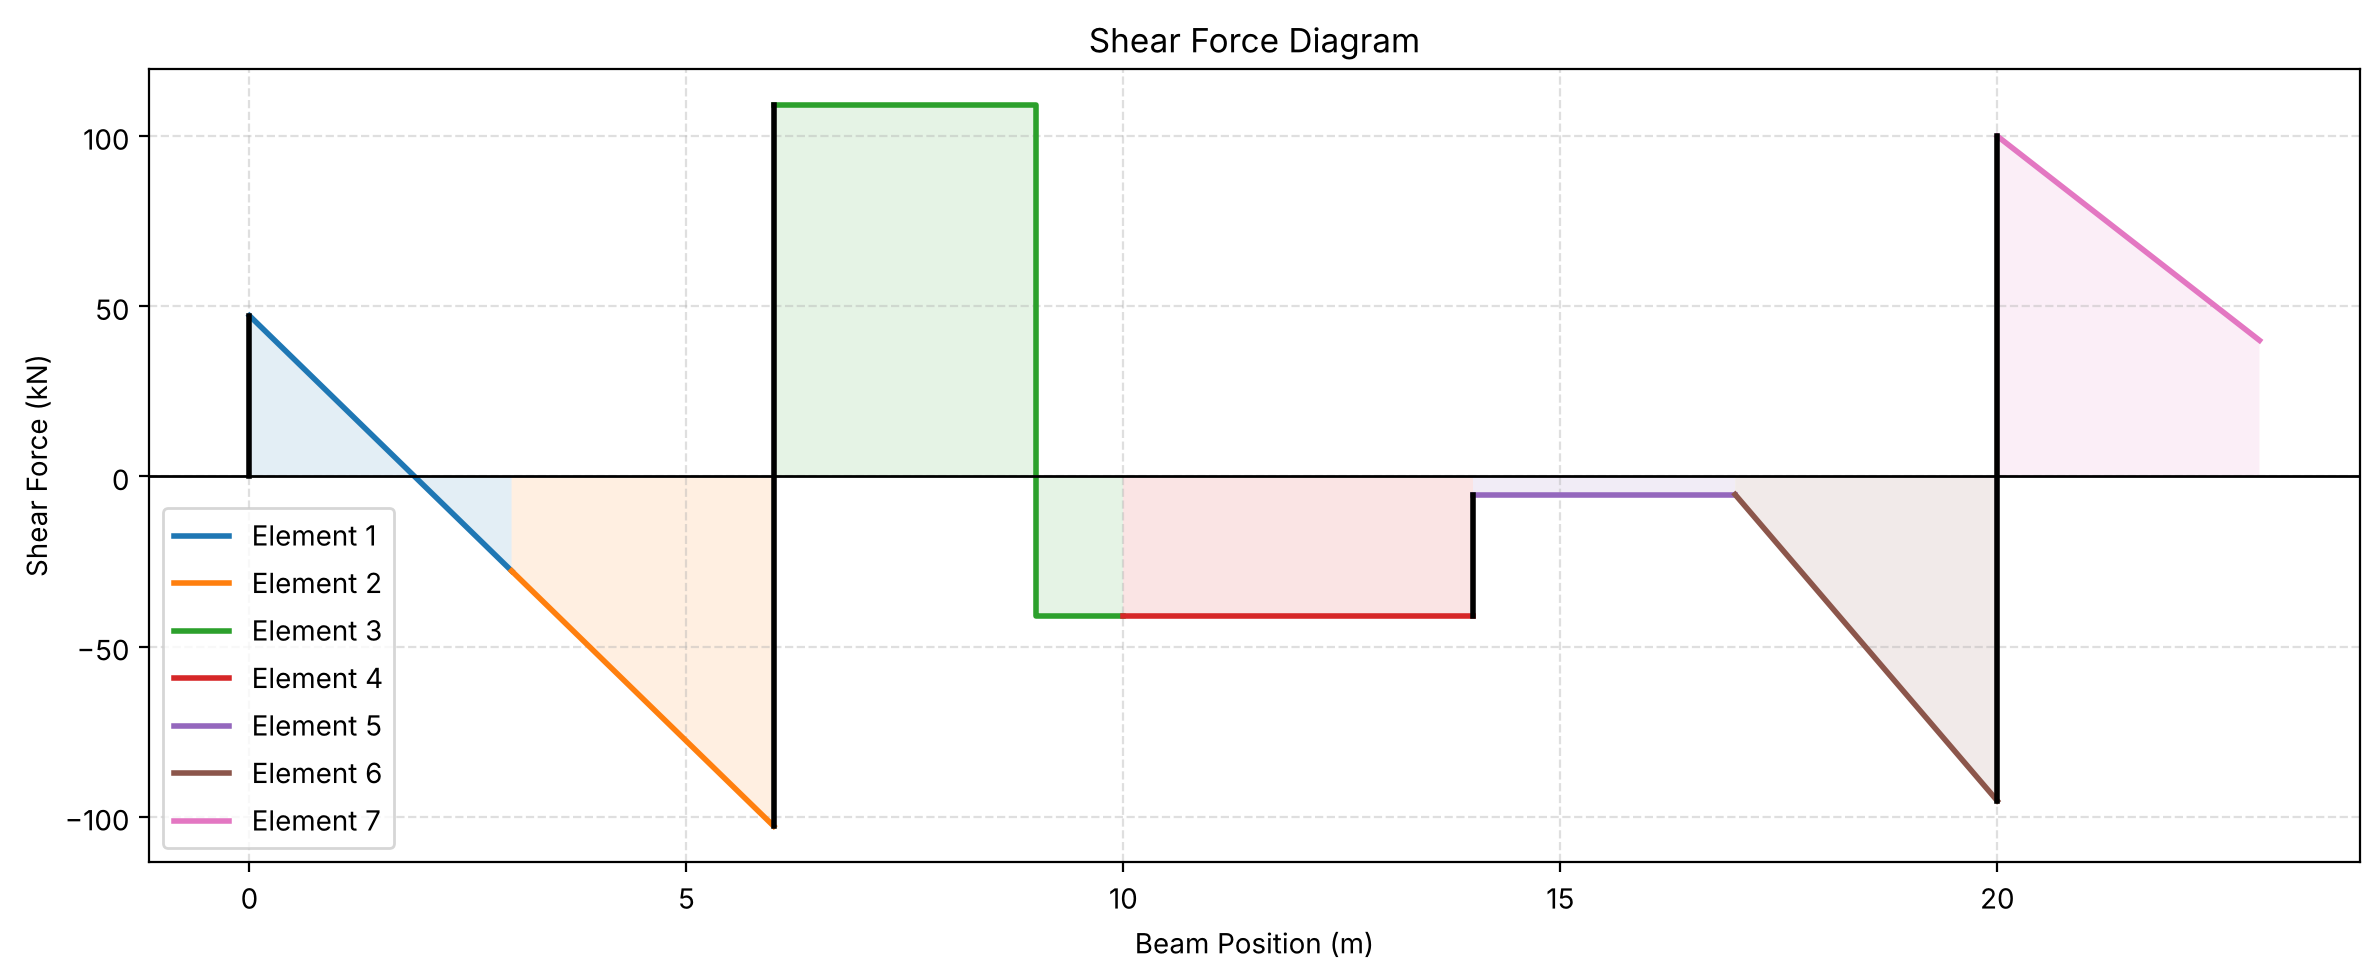

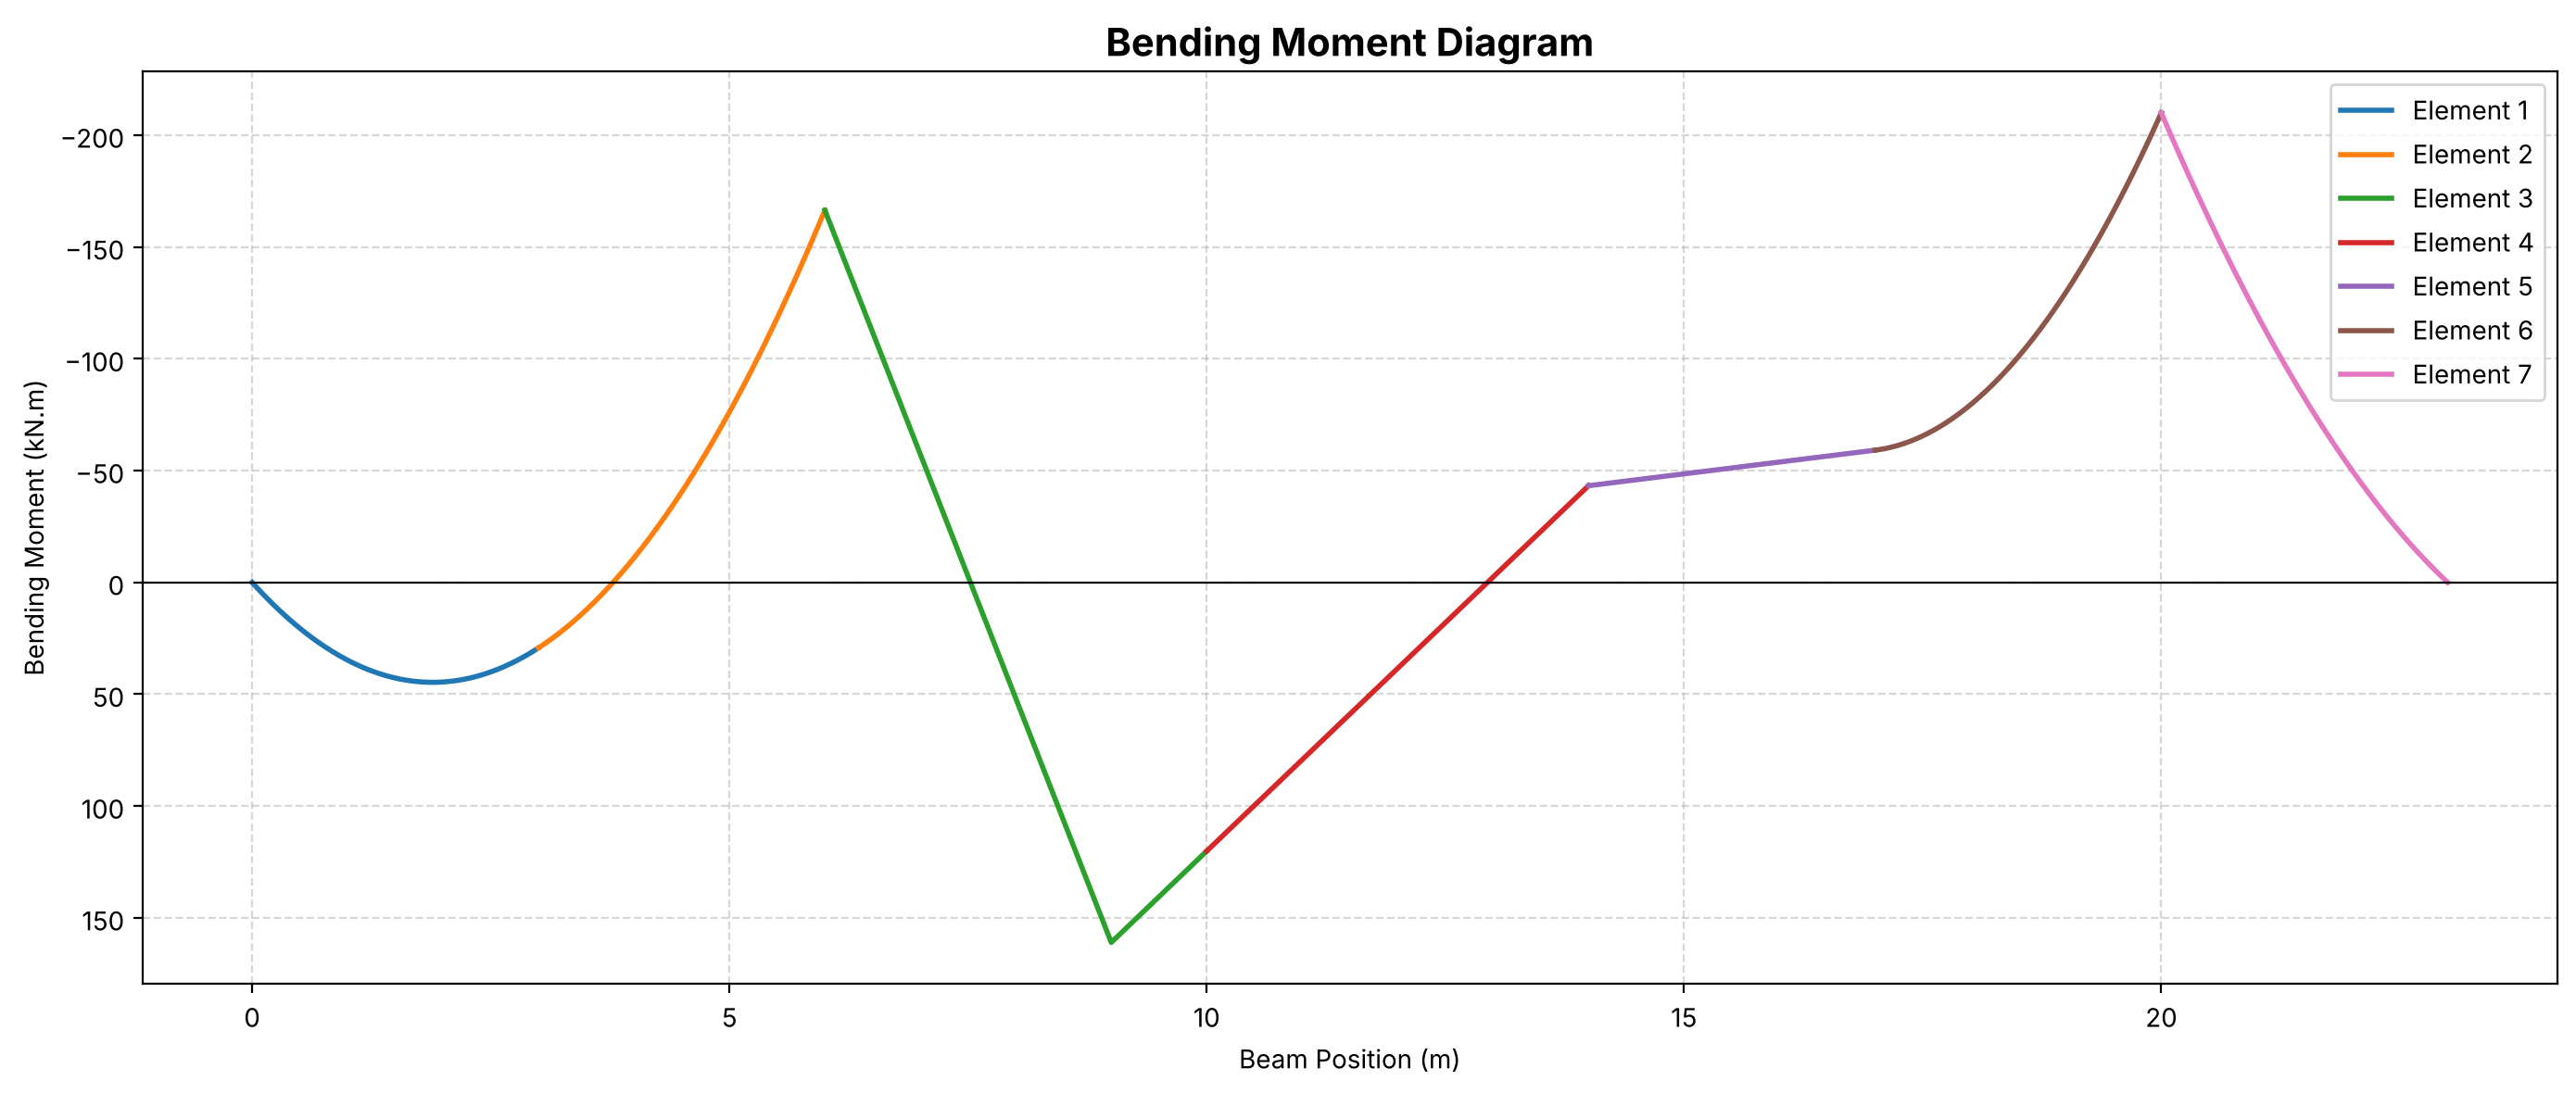

In [18]:
from benchmarks import register_example2
rec2 = register_example2(dsm)
print(len(rec2), "checks,", sum(not r["passed"] for r in rec2), "failed; largest absolute error",
      f"{max(r['absolute_error'] or 0 for r in rec2):.1e}")
dsm.plot_shear_force_diagram(beam2, res2["element_diagrams"])
dsm.plot_bending_moment_diagram(beam2, res2["element_diagrams"])

## 15. Limitations

* One constant EI per beam; vertical restraints only; no axial DOF.
* Internal point loads must be downward (P > 0) and lie strictly inside an element.
* Reported maximum deflections need the refinement check above; moments and reactions do not.
* The tests establish agreement with closed-form solutions, an independent Three-Moment
  solution and an independent exact force-method solution for the cases listed. They do not validate other structures.